
# AI Quality Engineering — MNIST Digit Recognition

## Phase 1: Baseline Model and Quality Evaluation

### Objective
Build a neural network that recognizes handwritten digits from 0 to 9 using the MNIST dataset.

### AI Quality Engineering objectives
1. Establish baseline model accuracy.
2. Monitor training and validation loss.
3. Identify overfitting and underfitting.
4. Evaluate generalization on unseen test data.
5. Save model artifacts and evaluation metrics for future phases.

### Dataset
- Training samples: 60,000
- Test samples: 10,000
- Image dimensions: 28 × 28 pixels
- Number of classes: 10 (digits 0–9)

### Planned workflow
1. Import libraries and configure reproducibility.
2. Load and inspect MNIST.
3. Prepare training and validation datasets.
4. Build a baseline neural network.
5. Train and evaluate the model.
6. Analyze quality metrics and save artifacts.


In [1]:

# Step 1: Import required libraries

import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

print("All libraries imported successfully!")
print("PyTorch version:", torch.__version__)


All libraries imported successfully!
PyTorch version: 2.14.1+cpu


In [2]:

# Step 2: Configure reproducibility and execution device

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PROJECT_ROOT = Path.cwd()

# If the notebook is launched from the notebooks directory,
# move one level up to the project root.
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports"

for directory in [DATA_DIR, MODEL_DIR, REPORT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Random seed:", SEED)
print("Execution device:", DEVICE)
print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)
print("Model directory:", MODEL_DIR)
print("Report directory:", REPORT_DIR)


Random seed: 42
Execution device: cpu
Project root: c:\vathsan\BITS\ai-quality-engineering-mnist-digit-recognition-project
Data directory: c:\vathsan\BITS\ai-quality-engineering-mnist-digit-recognition-project\data
Model directory: c:\vathsan\BITS\ai-quality-engineering-mnist-digit-recognition-project\models
Report directory: c:\vathsan\BITS\ai-quality-engineering-mnist-digit-recognition-project\reports



## Step 3: Load the MNIST Dataset

MNIST contains handwritten digit images representing classes 0 through 9.

We will use:
- **Training dataset:** 60,000 images for model development.
- **Test dataset:** 10,000 images reserved for final evaluation.

Each image is grayscale with dimensions of 28 × 28 pixels.

We convert each image into a PyTorch tensor, with pixel values normalized to the range [0, 1].


In [3]:

# Step 3: Load the MNIST dataset

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root=str(DATA_DIR),
    train=True,
    download=True,
    transform=transform,
)

test_dataset = datasets.MNIST(
    root=str(DATA_DIR),
    train=False,
    download=True,
    transform=transform,
)

print("MNIST dataset loaded successfully!")
print(f"Training samples: {len(train_dataset):,}")
print(f"Test samples: {len(test_dataset):,}")

# Inspect one training sample
image, label = train_dataset[0]

print("\nFirst training sample:")
print("Image shape:", tuple(image.shape))
print("Label:", label)
print("Minimum pixel value:", image.min().item())
print("Maximum pixel value:", image.max().item())


100.0%
100.0%
100.0%
100.0%


MNIST dataset loaded successfully!
Training samples: 60,000
Test samples: 10,000

First training sample:
Image shape: (1, 28, 28)
Label: 5
Minimum pixel value: 0.0
Maximum pixel value: 1.0



### Visual Inspection of MNIST Samples

We will visualize sample images and their labels to verify that the dataset contains recognizable handwritten digits.

Visual inspection is an initial data-quality check. It helps us detect unexpected shapes, incorrect labels, or unusual inputs before training.


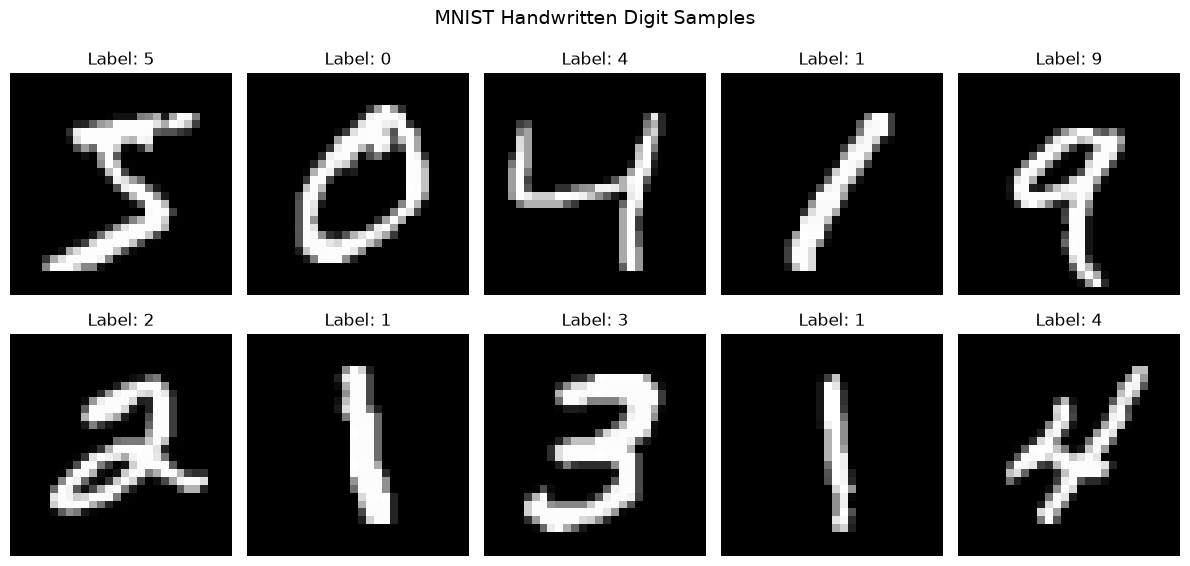

In [4]:

# Step 4: Visualize sample handwritten digits

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for index, ax in enumerate(axes.flat):
    image, label = train_dataset[index]

    ax.imshow(image.squeeze(0), cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

fig.suptitle("MNIST Handwritten Digit Samples", fontsize=14)
plt.tight_layout()
plt.show()


Training samples per digit:
Digit 0: 5,923
Digit 1: 6,742
Digit 2: 5,958
Digit 3: 6,131
Digit 4: 5,842
Digit 5: 5,421
Digit 6: 5,918
Digit 7: 6,265
Digit 8: 5,851
Digit 9: 5,949


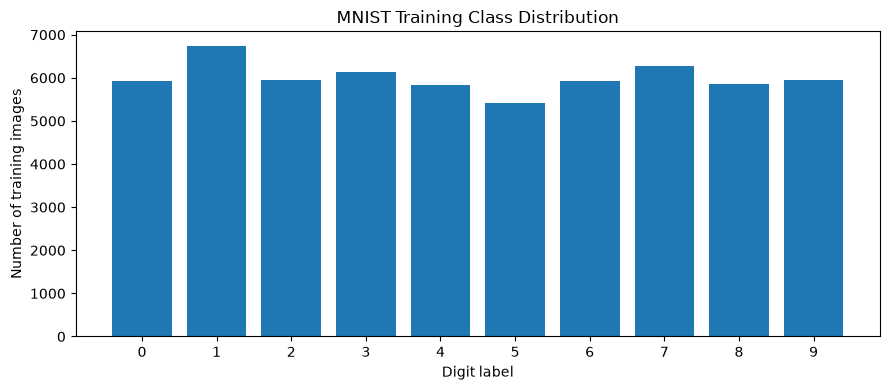

In [5]:

# Step 5: Check the distribution of digit labels

train_labels = train_dataset.targets
class_counts = torch.bincount(train_labels, minlength=10)

print("Training samples per digit:")
for digit, count in enumerate(class_counts.tolist()):
    print(f"Digit {digit}: {count:,}")

plt.figure(figsize=(9, 4))
plt.bar(range(10), class_counts.tolist())
plt.xticks(range(10))
plt.xlabel("Digit label")
plt.ylabel("Number of training images")
plt.title("MNIST Training Class Distribution")
plt.tight_layout()
plt.show()


In [7]:

# Step 6: Split training data into training and validation sets

from torch.utils.data import DataLoader, random_split

validation_size = 6000
training_size = len(train_dataset) - validation_size

train_subset, validation_subset = random_split(
    train_dataset,
    [training_size, validation_size],
    generator=torch.Generator().manual_seed(SEED),
)

print("Training samples:", len(train_subset))
print("Validation samples:", len(validation_subset))
print("Test samples:", len(test_dataset))


Training samples: 54000
Validation samples: 6000
Test samples: 10000


In [8]:

# Step 7: Create DataLoaders

BATCH_SIZE = 128

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)

validation_loader = DataLoader(
    validation_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Test batches:", len(test_loader))

# Inspect one batch
images, labels = next(iter(train_loader))

print("\nBatch image shape:", tuple(images.shape))
print("Batch label shape:", tuple(labels.shape))
print("First 10 labels:", labels[:10].tolist())


Training batches: 422
Validation batches: 47
Test batches: 79

Batch image shape: (128, 1, 28, 28)
Batch label shape: (128,)
First 10 labels: [2, 0, 9, 9, 1, 8, 3, 6, 9, 1]


### Baseline Model Architecture

In [9]:

# Step 8: Define the baseline neural network

class MNISTBaseline(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            nn.Linear(64, 10),
        )

    def forward(self, x):
        return self.network(x)


model = MNISTBaseline().to(DEVICE)

print(model)

total_parameters = sum(
    parameter.numel() for parameter in model.parameters()
)

print("\nTotal trainable parameters:", total_parameters)
print("Model device:", next(model.parameters()).device)


MNISTBaseline(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=64, out_features=10, bias=True)
  )
)

Total trainable parameters: 109386
Model device: cpu


In [10]:

# Step 9: Configure loss function and optimizer

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])


Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001



## Step 10: Train the Baseline Model

During training:
- The model learns from batches of training images.
- Backpropagation calculates gradients.
- Adam updates model parameters.
- Validation metrics are measured after each epoch without updating the weights.

We will track training loss, validation loss, and validation accuracy to evaluate learning and generalization.


In [11]:

# Step 10: Train and validate the baseline model

EPOCHS = 10

history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
}


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    total_samples = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        # Clear gradients from the previous batch
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backpropagation and weight update
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples


def evaluate_model(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            predictions = outputs.argmax(dim=1)

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (predictions == labels).sum().item()
            total_samples += batch_size

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    return average_loss, accuracy


for epoch in range(EPOCHS):
    train_loss = train_one_epoch(
        model, train_loader, criterion, optimizer, DEVICE
    )

    val_loss, val_accuracy = evaluate_model(
        model, validation_loader, criterion, DEVICE
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2%}"
    )

print("\nTraining completed!")


Epoch [01/10] | Train Loss: 0.4835 | Val Loss: 0.2390 | Val Accuracy: 92.75%
Epoch [02/10] | Train Loss: 0.2052 | Val Loss: 0.1712 | Val Accuracy: 94.70%
Epoch [03/10] | Train Loss: 0.1466 | Val Loss: 0.1304 | Val Accuracy: 96.02%
Epoch [04/10] | Train Loss: 0.1148 | Val Loss: 0.1137 | Val Accuracy: 96.53%
Epoch [05/10] | Train Loss: 0.0917 | Val Loss: 0.1019 | Val Accuracy: 96.92%
Epoch [06/10] | Train Loss: 0.0767 | Val Loss: 0.0989 | Val Accuracy: 97.08%
Epoch [07/10] | Train Loss: 0.0639 | Val Loss: 0.0877 | Val Accuracy: 97.42%
Epoch [08/10] | Train Loss: 0.0535 | Val Loss: 0.0835 | Val Accuracy: 97.62%
Epoch [09/10] | Train Loss: 0.0466 | Val Loss: 0.0854 | Val Accuracy: 97.37%
Epoch [10/10] | Train Loss: 0.0388 | Val Loss: 0.0865 | Val Accuracy: 97.37%

Training completed!


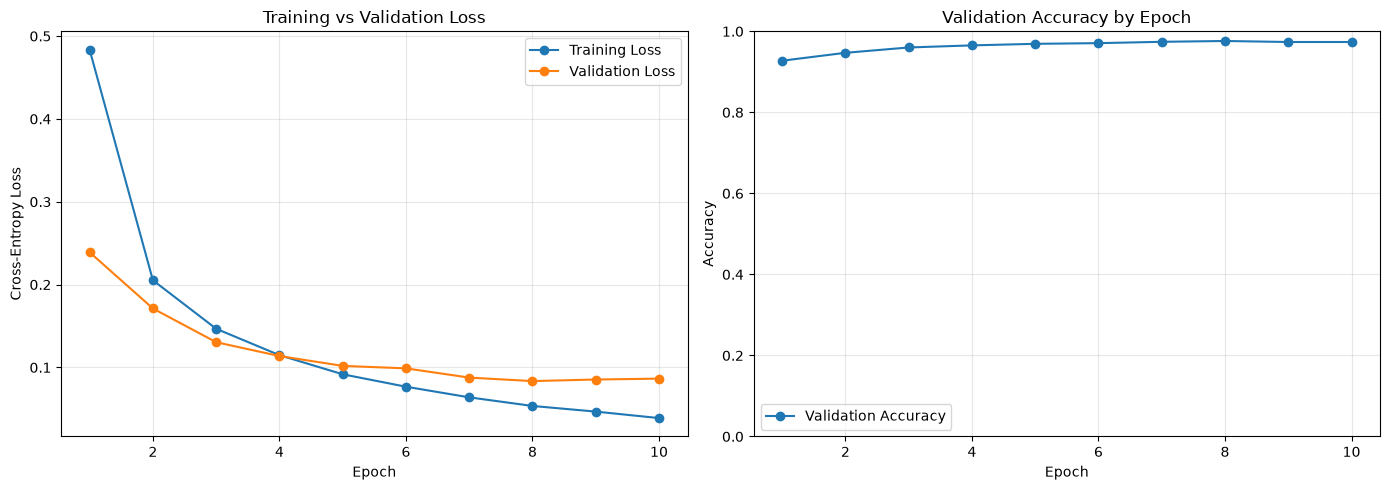

In [13]:

# Step 11: Plot training and validation metrics

epochs_range = range(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    epochs_range, history["train_loss"],
    marker="o", label="Training Loss"
)
axes[0].plot(
    epochs_range, history["val_loss"],
    marker="o", label="Validation Loss"
)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    epochs_range,
    history["val_accuracy"],
    marker="o",
    label="Validation Accuracy",
)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Validation Accuracy by Epoch")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



### Baseline Training Observations

- Training loss decreased throughout the training process.
- Validation accuracy improved substantially during the early epochs.
- Validation accuracy approached a plateau in the later epochs.
- Validation loss began to rise slightly after reaching a minimum, while training loss continued to decrease.
- This pattern suggests possible mild overfitting during later epochs.

Next steps:
- Evaluate the model on the independent test dataset.
- Analyze per-class precision, recall and the confusion matrix.
- Investigate whether selecting the best validation checkpoint improves generalization.


In [14]:

# Step 12: Final evaluation on the independent test dataset

test_loss, test_accuracy = evaluate_model(
    model,
    test_loader,
    criterion,
    DEVICE,
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")
print(f"Correct predictions: {round(test_accuracy * len(test_dataset)):,}")
print(f"Incorrect predictions: {len(test_dataset) - round(test_accuracy * len(test_dataset)):,}")


Test Loss: 0.0782
Test Accuracy: 97.76%
Correct predictions: 9,776
Incorrect predictions: 224


In [15]:

# Step 13: Detailed classification evaluation

all_predictions = []
all_true_labels = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().tolist())
        all_true_labels.extend(labels.tolist())

print("Classification Report:\n")

print(
    classification_report(
        all_true_labels,
        all_predictions,
        labels=list(range(10)),
        target_names=[str(digit) for digit in range(10)],
        digits=4,
        zero_division=0,
    )
)


Classification Report:

              precision    recall  f1-score   support

           0     0.9827    0.9827    0.9827       980
           1     0.9877    0.9938    0.9908      1135
           2     0.9813    0.9641    0.9726      1032
           3     0.9697    0.9832    0.9764      1010
           4     0.9766    0.9766    0.9766       982
           5     0.9809    0.9809    0.9809       892
           6     0.9842    0.9729    0.9785       958
           7     0.9591    0.9815    0.9702      1028
           8     0.9723    0.9713    0.9718       974
           9     0.9819    0.9673    0.9745      1009

    accuracy                         0.9776     10000
   macro avg     0.9776    0.9774    0.9775     10000
weighted avg     0.9777    0.9776    0.9776     10000



In [18]:

# Step 15: Save baseline model and evaluation artifacts

import json
from datetime import datetime, timezone

# Save trained model weights
model_path = MODEL_DIR / "mnist_baseline.pth"
torch.save(model.state_dict(), model_path)

# Prepare metrics for saving
report_dict = classification_report(
    all_true_labels,
    all_predictions,
    labels=list(range(10)),
    output_dict=True,
    zero_division=0,
)

baseline_results = {
    "experiment": "MNIST Baseline Model",
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "seed": SEED,
    "architecture": "MLP: 784 -> 128 -> 64 -> 10",
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": 0.001,
    "optimizer": "Adam",
    "loss_function": "CrossEntropyLoss",
    "training_samples": len(train_subset),
    "validation_samples": len(validation_subset),
    "test_samples": len(test_dataset),
    "test_loss": test_loss,
    "test_accuracy": test_accuracy,
    "classification_report": report_dict,
    "training_history": history,
}

metrics_path = REPORT_DIR / "baseline_metrics.json"

with open(metrics_path, "w", encoding="utf-8") as file:
    json.dump(baseline_results, file, indent=4)

print("Baseline artifacts saved successfully!")
print("Model weights:", model_path)
print("Evaluation metrics:", metrics_path)
confusion_matrix_path = REPORT_DIR / "baseline_confusion_matrix.png"
print("Confusion matrix:", confusion_matrix_path)
print(f"Test accuracy: {test_accuracy:.2%}")
print(f"Test loss: {test_loss:.4f}")


Baseline artifacts saved successfully!
Model weights: c:\vathsan\BITS\ai-quality-engineering-mnist-digit-recognition-project\models\mnist_baseline.pth
Evaluation metrics: c:\vathsan\BITS\ai-quality-engineering-mnist-digit-recognition-project\reports\baseline_metrics.json
Confusion matrix: c:\vathsan\BITS\ai-quality-engineering-mnist-digit-recognition-project\reports\baseline_confusion_matrix.png
Test accuracy: 97.76%
Test loss: 0.0782


In [22]:
# Step 16: Verify saved artifacts

artifacts = {
    "Model weights": MODEL_DIR / "mnist_baseline.pth",
    "Evaluation metrics": REPORT_DIR / "baseline_metrics.json",
    "Confusion matrix": REPORT_DIR / "baseline_confusion_matrix.png",
}

for name, path in artifacts.items():
    print(f"{name}: {'EXISTS' if path.exists() else 'MISSING'}")
    if path.exists():
        print(f"  Size: {path.stat().st_size:,} bytes")

with open(REPORT_DIR / "baseline_metrics.json", "r", encoding="utf-8") as file:
    saved_results = json.load(file)

print("\nSaved test accuracy:", f"{saved_results['test_accuracy']:.2%}")
print("Saved test loss:", f"{saved_results['test_loss']:.4f}")

Model weights: EXISTS
  Size: 440,745 bytes
Evaluation metrics: EXISTS
  Size: 3,980 bytes
Confusion matrix: EXISTS
  Size: 70,696 bytes

Saved test accuracy: 97.76%
Saved test loss: 0.0782


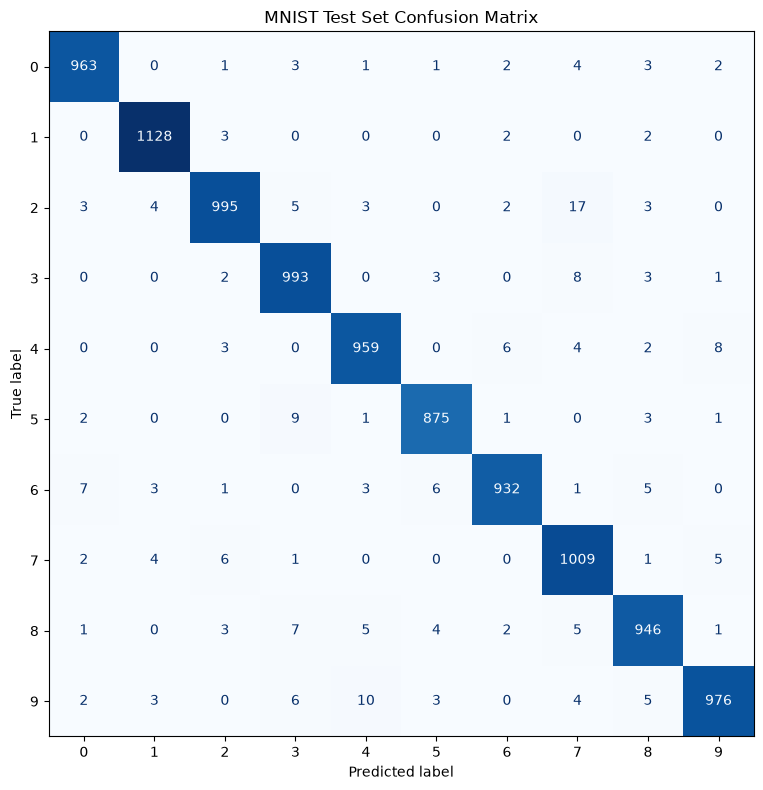

Confusion matrix saved: c:\vathsan\BITS\ai-quality-engineering-mnist-digit-recognition-project\reports\baseline_confusion_matrix.png
File exists: True
File size: 70696 bytes


In [20]:

# Step 17: Regenerate and save the confusion matrix

from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(
    all_true_labels,
    all_predictions,
    labels=list(range(10)),
)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(range(10)),
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False,
)

ax.set_title("MNIST Test Set Confusion Matrix")
plt.tight_layout()

confusion_matrix_path = REPORT_DIR / "baseline_confusion_matrix.png"

fig.savefig(
    confusion_matrix_path,
    dpi=150,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print("Confusion matrix saved:", confusion_matrix_path)
print("File exists:", confusion_matrix_path.exists())
print("File size:", confusion_matrix_path.stat().st_size, "bytes")
